#**UNIVERSIDAD MAYOR**

##**Machine Learning**

##Trabajo Sumativo Unidad 3
##Ingeniería Civil Industrial


###Integrantes:

*   Camilo Cáceres
*   Nicolás Cruz
*   Bruno Yáñez

Asignatura:
Machine Learning

Docente:
Franco Mansilla

Fecha
11.10.2026



# Introducción

Durante las unidades anteriores se desarrolló un pipeline de aprendizaje supervisado para la predicción de PM2.5.

En esta tercera etapa se exploran técnicas de aprendizaje no supervisado con el objetivo de identificar agrupamientos naturales en los datos sin utilizar la variable objetivo durante el entrenamiento.

Se evaluarán distintos algoritmos de clustering basados en distancia y densidad, comparando además el efecto de la reducción de dimensionalidad mediante PCA sobre la calidad de los agrupamientos obtenidos.

In [2]:
# librerías

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

from sklearn.cluster import (
    KMeans,
    AgglomerativeClustering,
    Birch,
    DBSCAN,
    OPTICS
)

from sklearn.metrics import (
    silhouette_score,
    silhouette_samples,
    calinski_harabasz_score,
    davies_bouldin_score
)

In [3]:
#carga datos

df = pd.read_csv("datos.csv")

print(df.shape)

df.head()

(1320, 8)


,SO2,NO2,O3,Temperature,Humidity,Pressure,WindSpeed,PM2_5
0,42.53,52.78,34.22,1.7,62.8,1019.3,4.60,50.5
1,34.65,2.74,2.02,18.0,34.0,1014.8,25.56,10.0
2,46.10,57.51,40.13,-8.2,37.7,1002.7,6.79,34.9
3,27.58,39.51,51.83,10.1,64.0,1013.8,1.96,43.4
4,50.75,34.28,60.04,35.1,67.5,1011.1,1.91,49.4


In [4]:
# winsorizacion de acuerdo a TSU1

for c in df.columns:

    p1 = df[c].quantile(0.01)

    p99 = df[c].quantile(0.99)

    df[c] = df[c].clip(
        lower=p1,
        upper=p99
    )

In [5]:
tipos_datos = pd.DataFrame(
    df.dtypes,
    columns=["Tipo"]
)

display(tipos_datos)

,Tipo
SO2,float64
NO2,float64
O3,float64
Temperature,float64
Humidity,float64
Pressure,float64
WindSpeed,float64
PM2_5,float64


In [6]:
columnas_no_numericas = df.select_dtypes(
    exclude=np.number
).columns.tolist()

print("Variables no numéricas:")
print(columnas_no_numericas)

Variables no numéricas:
[]


No existen variable no numéricas para el df, por lo que no amerita emplear One Hot Encoding.

In [7]:
# Guardamos pm2.5 para interpretaicon de clusters

pm25 = df["PM2_5"].copy()

X = df.drop(
    columns=["PM2_5"]
)

In [8]:
# Normalización

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

In [9]:
# Varianza

varianzas = X.var().sort_values()

display(
    varianzas.to_frame(
        "Varianza"
    )
)

,Varianza
WindSpeed,25.009661
Pressure,93.749542
Temperature,137.039385
Humidity,383.958099
O3,403.044834
SO2,408.945198
NO2,597.965111


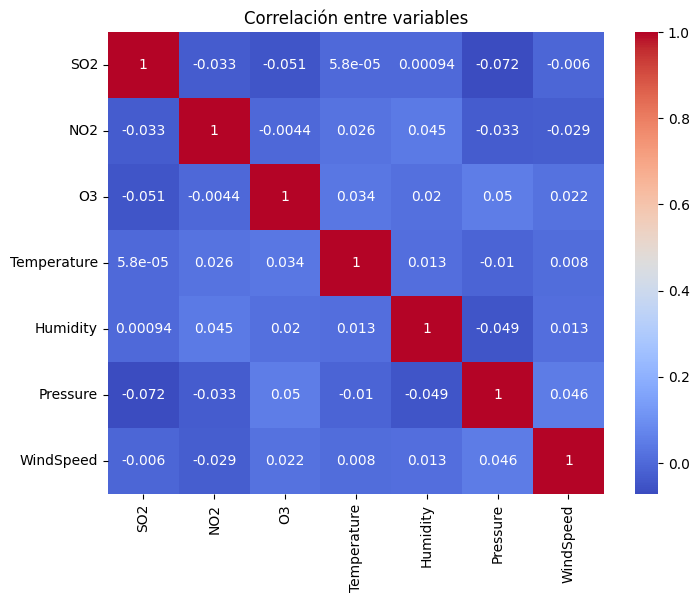

In [10]:
# correlacion y heatmap

plt.figure(figsize=(8,6))

sns.heatmap(
    X.corr(),
    annot=True,
    cmap="coolwarm"
)

plt.title(
    "Correlación entre variables"
)

plt.show()

In [11]:
#PCA

pca_full = PCA()

pca_full.fit(X_scaled)

var_exp = pca_full.explained_variance_ratio_

var_acum = np.cumsum(var_exp)

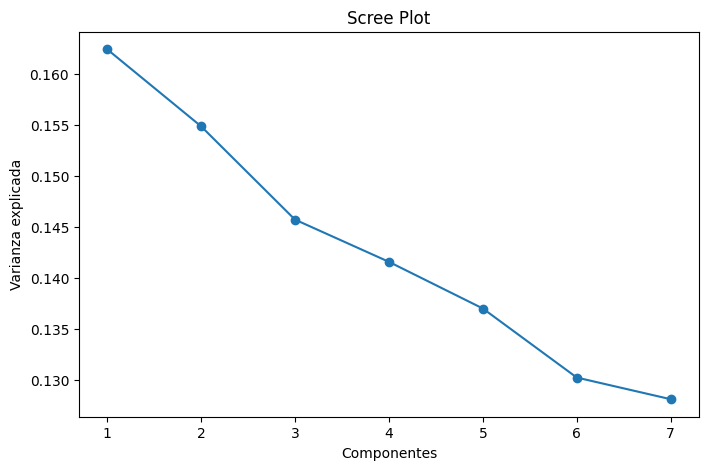

In [12]:
# Scree Plot

plt.figure(figsize=(8,5))

plt.plot(
    range(1, len(var_exp)+1),
    var_exp,
    marker="o"
)

plt.xlabel("Componentes")
plt.ylabel("Varianza explicada")

plt.title("Scree Plot")

plt.show()

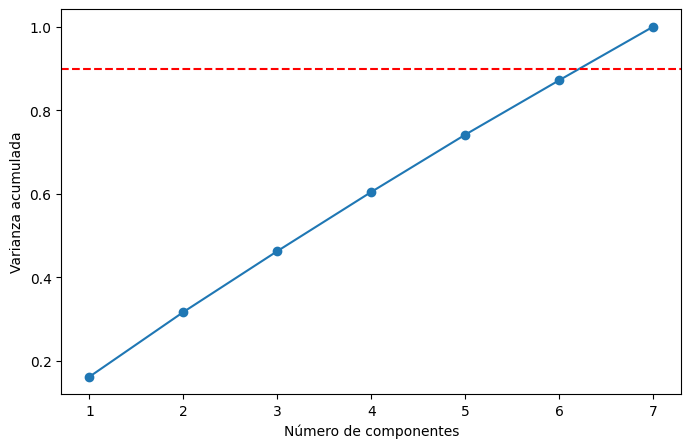

In [13]:
#var acum

plt.figure(figsize=(8,5))

plt.plot(
    range(1, len(var_acum)+1),
    var_acum,
    marker="o"
)

plt.axhline(
    0.90,
    linestyle="--",
    color="red"
)

plt.xlabel("Número de componentes")
plt.ylabel("Varianza acumulada")

plt.show()

In [14]:
# Componentes necesarios

n_comp = np.argmax(
    var_acum >= 0.90
) + 1

print(
    "Componentes necesarios:",
    n_comp
)

Componentes necesarios: 7


In [15]:
# PCA final

pca = PCA(
    n_components=n_comp
)

X_pca = pca.fit_transform(
    X_scaled
)

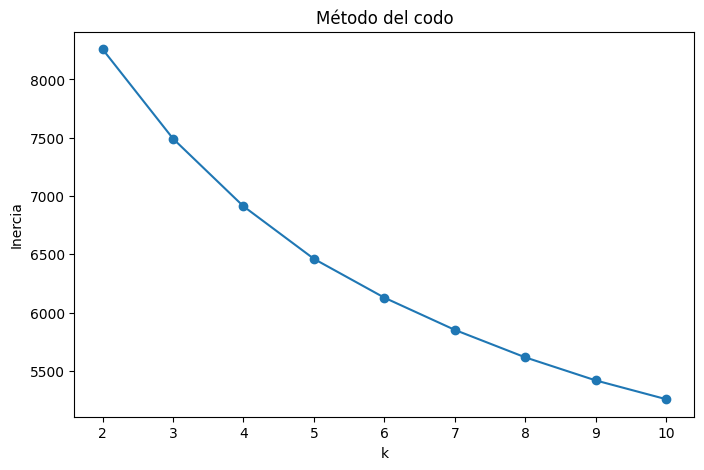

In [16]:
# metodo del codo

inercias = []

for k in range(2,11):

    modelo = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    modelo.fit(X_scaled)

    inercias.append(
        modelo.inertia_
    )

plt.figure(figsize=(8,5))

plt.plot(
    range(2,11),
    inercias,
    marker="o"
)

plt.xlabel("k")
plt.ylabel("Inercia")

plt.title("Método del codo")

plt.show()

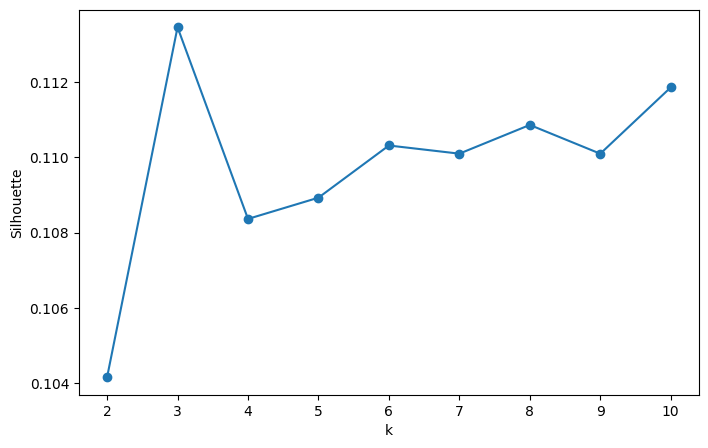

In [17]:
# silhouette

sil_scores = []

for k in range(2,11):

    km = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    labels = km.fit_predict(
        X_scaled
    )

    sil_scores.append(

        silhouette_score(
            X_scaled,
            labels
        )

    )

plt.figure(figsize=(8,5))

plt.plot(
    range(2,11),
    sil_scores,
    marker="o"
)

plt.xlabel("k")
plt.ylabel("Silhouette")

plt.show()

In [18]:
# k optimo

k_opt = np.argmax(
    sil_scores
) + 2

print(k_opt)

3


El análisis del índice Silhouette mostró su valor máximo para k=3, por lo que se seleccionó este número de grupos para el entrenamiento de los algoritmos basados en distancia.

In [19]:
# f de evaluacion

def evaluar_clustering(X, labels):

    clusters_validos = np.unique(labels)

    clusters_validos = clusters_validos[
        clusters_validos != -1
    ]

    if len(clusters_validos) < 2:

        return (
            np.nan,
            np.nan,
            np.nan
        )

    sil = silhouette_score(
        X,
        labels
    )

    ch = calinski_harabasz_score(
        X,
        labels
    )

    db = davies_bouldin_score(
        X,
        labels
    )

    return sil, ch, db

In [20]:
# Benchmarking sin PCA

modelos = {

    "KMeans":
        KMeans(
            n_clusters=k_opt,
            random_state=42,
            n_init=20
        ),

    "Agglomerative":
        AgglomerativeClustering(
            n_clusters=k_opt
        ),

    "Birch":
        Birch(
            n_clusters=k_opt
        ),

    "DBSCAN":
        DBSCAN(
            eps=0.8,
            min_samples=5
        ),

    "OPTICS":
        OPTICS(
            min_samples=5
        )

}

In [21]:
resultados_sin_pca = []

for nombre, modelo in modelos.items():

    labels = modelo.fit_predict(
        X_scaled
    )

    sil, ch, db = evaluar_clustering(
        X_scaled,
        labels
    )

    resultados_sin_pca.append([
        nombre,
        sil,
        ch,
        db
    ])

In [22]:
resultados_sin_pca = pd.DataFrame(

    resultados_sin_pca,

    columns=[
        "Modelo",
        "Silhouette",
        "Calinski",
        "Davies"
    ]
)

resultados_sin_pca["PCA"] = "No"

resultados_sin_pca.round(3)

,Modelo,Silhouette,Calinski,Davies,PCA
0,KMeans,0.113,153.648,2.381,No
1,Agglomerative,0.050,94.289,2.906,No
2,Birch,0.066,101.243,3.057,No
3,DBSCAN,-0.249,1.316,2.580,No
4,OPTICS,-0.315,2.247,2.153,No


In [23]:
# benchmarking con PCA

resultados_pca = []

for nombre, modelo in modelos.items():

    labels = modelo.fit_predict(
        X_pca
    )

    sil, ch, db = evaluar_clustering(
        X_pca,
        labels
    )

    resultados_pca.append([
        nombre,
        sil,
        ch,
        db
    ])

In [24]:
resultados_pca = pd.DataFrame(

    resultados_pca,

    columns=[
        "Modelo",
        "Silhouette",
        "Calinski",
        "Davies"
    ]
)

resultados_pca["PCA"] = "Sí"

resultados_pca.round(3)

,Modelo,Silhouette,Calinski,Davies,PCA
0,KMeans,0.113,153.648,2.381,Sí
1,Agglomerative,0.050,94.289,2.906,Sí
2,Birch,0.066,101.243,3.057,Sí
3,DBSCAN,-0.249,1.316,2.580,Sí
4,OPTICS,-0.315,2.247,2.153,Sí


In [25]:
# bechmark global

benchmark = pd.concat([

    resultados_sin_pca,

    resultados_pca

])

benchmark = benchmark.sort_values(
    by="Silhouette",
    ascending=False
)

benchmark.round(3)

,Modelo,Silhouette,Calinski,Davies,PCA
0,KMeans,0.113,153.648,2.381,Sí
0,KMeans,0.113,153.648,2.381,No
2,Birch,0.066,101.243,3.057,Sí
2,Birch,0.066,101.243,3.057,No
1,Agglomerative,0.050,94.289,2.906,Sí
1,Agglomerative,0.050,94.289,2.906,No
3,DBSCAN,-0.249,1.316,2.580,Sí
3,DBSCAN,-0.249,1.316,2.580,No
4,OPTICS,-0.315,2.247,2.153,No
4,OPTICS,-0.315,2.247,2.153,Sí


In [26]:
# Modelo ganador

benchmark.head()

,Modelo,Silhouette,Calinski,Davies,PCA
0,KMeans,0.113450,153.647748,2.380808,Sí
0,KMeans,0.113450,153.647748,2.380808,No
2,Birch,0.065822,101.242981,3.056744,Sí
2,Birch,0.065822,101.242981,3.056744,No
1,Agglomerative,0.050153,94.289361,2.905670,Sí


In [27]:
kmeans_final = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=20
)

labels_final = kmeans_final.fit_predict(
    X_scaled
)

In [28]:
df_clusters = df.copy()

df_clusters["cluster"] = labels_final

In [29]:
cluster_pm25 = df_clusters.groupby(
    "cluster"
)["PM2_5"].describe()

cluster_pm25

,count,mean,std,min,25%,50%,75%,max
cluster,,,,,,,,
0,214.0,21.591589,13.274923,10.0,10.000,16.80,30.850,61.100
1,552.0,58.057565,16.849038,14.9,46.925,57.55,69.325,95.148
2,554.0,44.010282,17.957526,10.0,31.450,43.60,55.800,95.148


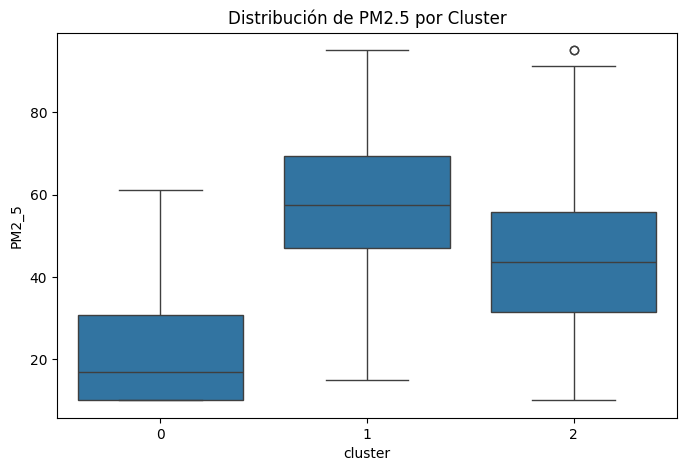

In [30]:
plt.figure(figsize=(8,5))

sns.boxplot(
    x="cluster",
    y="PM2_5",
    data=df_clusters
)

plt.title(
    "Distribución de PM2.5 por Cluster"
)

plt.show()

## Interpretación de los clusters mediante PM2.5

Si bien la variable PM2.5 no fue utilizada durante el entrenamiento de los algoritmos de clustering, puede utilizarse posteriormente para interpretar los grupos identificados.

Los resultados muestran diferencias relevantes entre los clusters obtenidos. El cluster 0 presentó una concentración media de PM2.5 de 21.59 ug/m3, mientras que el cluster 2 alcanzó 44.01 ug/m3 y el cluster 1 presentó la mayor concentración promedio con 58.06 ug/m3.

La distribución observada en el boxplot confirma la existencia de perfiles diferenciados de contaminación atmosférica. Esto sugiere que el algoritmo fue capaz de identificar agrupamientos ambientalmente relevantes únicamente a partir de las variables meteorológicas y contaminantes utilizadas como predictores.

Por lo tanto, puede concluirse que la segmentación obtenida resulta consistente con la variable PM2.5 y permite distinguir observaciones asociadas a niveles bajos, medios y altos de contaminación.

In [31]:
cluster_summary = df_clusters.groupby(
    "cluster"
)["PM2_5"].agg(
    ["count","mean","median","std"]
).round(2)

cluster_summary

,count,mean,median,std
cluster,,,,
0,214,21.59,16.80,13.27
1,552,58.06,57.55,16.85
2,554,44.01,43.60,17.96


* Cluster 0:	Baja contaminación atmosférica
* Cluster 1:	Alta contaminación atmosférica
* Cluster 2:	Contaminación intermedia


Los resultados permiten identificar tres perfiles ambientales diferenciados.

El Cluster 0 presentó una concentración promedio de PM2.5 de 21.59 ug/m3, correspondiente a condiciones de baja contaminación.

El Cluster 2 presentó una concentración promedio de 44.01 ug/m3, representando condiciones intermedias.

Finalmente, el Cluster 1 concentró los mayores niveles de contaminación, con una media de 58.06 ug/m3.

Esto sugiere que el algoritmo fue capaz de identificar patrones ambientales relevantes utilizando únicamente variables meteorológicas y contaminantes atmosféricos, sin utilizar PM2.5 durante el entrenamiento.

1. Se aplicó un proceso completo de preparación de datos, manteniendo la estrategia de winsorización definida en la Unidad 1 para reducir la influencia de valores extremos sin eliminar registros.

2. No fue necesario aplicar One-Hot Encoding debido a que todas las variables predictoras correspondían a variables numéricas continuas.

3. La normalización mediante StandardScaler resultó necesaria para evitar que variables con diferentes escalas dominaran artificialmente el proceso de clustering.

4. La reducción de dimensionalidad mediante PCA fue evaluada utilizando análisis de varianza explicada y scree plot, seleccionándose el número mínimo de componentes capaz de conservar al menos el 90% de la información original.

5. La comparación entre las bases con y sin PCA mostró resultados prácticamente equivalentes, indicando que la reducción de dimensionalidad no modificó sustancialmente la estructura del conjunto de datos.

6. Se evaluaron cinco algoritmos de clustering, incluyendo enfoques basados en distancia (KMeans, Agglomerative y Birch) y densidad (DBSCAN y OPTICS).

7. KMeans presentó el mejor desempeño global según Silhouette Score (0.113), además de obtener los mejores resultados relativos en Calinski-Harabasz y Davies-Bouldin.

8. Los algoritmos basados en densidad presentaron un desempeño inferior para este conjunto de datos, probablemente debido a la ausencia de estructuras densas claramente diferenciadas.

9. La interpretación de los clusters utilizando PM2.5 reveló tres perfiles ambientales claramente diferenciados: baja contaminación, contaminación intermedia y alta contaminación.

10. Los resultados obtenidos demuestran que el aprendizaje no supervisado permite identificar patrones relevantes de calidad del aire incluso sin utilizar la variable objetivo durante el entrenamiento.